In [1]:
#let's study context windows of llm

In [5]:

from transformers import AutoTokenizer, AutoModelForCausalLM

model_name = "distilgpt2"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(model_name)

# Inspect model configuration
print("Model:", model_name)

print(
    "Maximum position embeddings:",
    model.config.max_position_embeddings
)

print(
    "Tokenizer vocabulary:",
    tokenizer.vocab_size
)

# Test different prompts
texts = [
    "Hello",
    "Explain artificial intelligence.",
    "Explain transformers, attention, and KV cache in detail."
]

for text in texts:

    tokens = tokenizer(
        text,
        return_tensors="pt"
    )

    print("\nText:", text)

    print("Token count:", tokens["input_ids"].shape[1])

    print("Token IDs:", tokens["input_ids"].tolist())

# Inspect output budget
max_new_tokens = 100

print("\nRequested output tokens:", max_new_tokens)


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Model: distilgpt2
Maximum position embeddings: 1024
Tokenizer vocabulary: 50257

Text: Hello
Token count: 1
Token IDs: [[15496]]

Text: Explain artificial intelligence.
Token count: 5
Token IDs: [[18438, 391, 11666, 4430, 13]]

Text: Explain transformers, attention, and KV cache in detail.
Token count: 14
Token IDs: [[18438, 391, 6121, 364, 11, 3241, 11, 290, 509, 53, 12940, 287, 3703, 13]]

Requested output tokens: 100


In [6]:
#let's see we createa very very very long long input

text= "artififcial intelligence is fascinating ,but not more than saksham"*500
tokens=tokenizer(text, return_tensors="pt")


print("orignial token count",tokens["input_ids"].shape[1])

#truncate to 1024 tokens
limited_tokens= tokenizer(
    text,
    return_tensors="pt",
    max_lenght=1024,
    truncation=True
)

print("after truncation :", limited_tokens["input_ids"].shape[1])


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (8000 > 1024). Running this sequence through the model will result in indexing errors


orignial token count 8000
after truncation : 1024


In [9]:
input_length = limited_tokens["input_ids"].shape[1]
max_new_tokens = 100

print("Total requested:", input_length + max_new_tokens)


Total requested: 1124


Line-by-Line Breakdown
input_length = limited_tokens["input_ids"].shape[1]

limited_tokens["input_ids"] is a 2D tensor of token IDs with shape (batch_size, sequence_length).

Index 0 is the batch size (here, 1 prompt), and index 1 (shape[1]) is how many tokens are in your truncated prompt (1024 in the DistilGPT-2 example).

max_new_tokens = 100

This sets how many new tokens you want the model to generate in its answer.

print("Total requested:", input_length + max_new_tokens)

Adds the prompt tokens and requested output tokens together: 1024 + 100 = 1124.

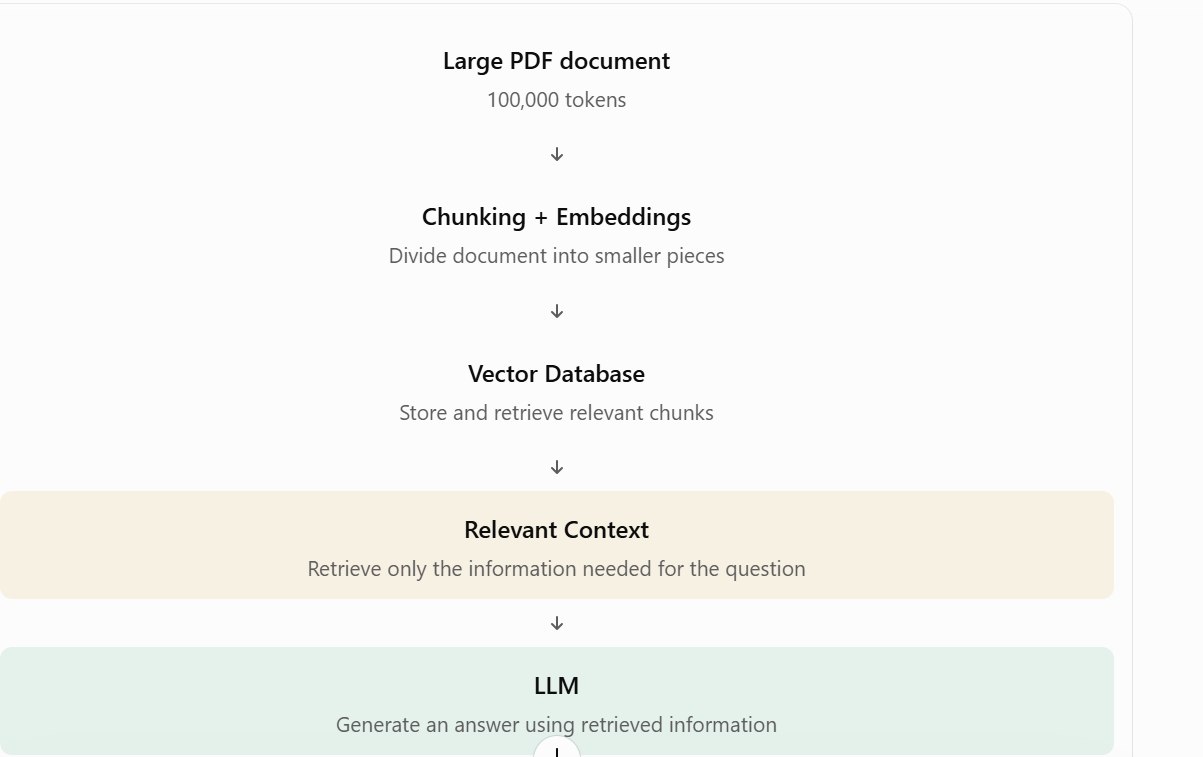